# CS5785 Midterm Project 2026

This notebook includes baseline models and code for preparing the two Kaggle submissions. See the project PDF for the full requirements.

## Load the data

Use the project `.venv/bin/python` kernel. The CSV files are in `part1-data/` and `part2-data/` inside the midterm folder. Run from this folder or the parent workspace root. Baseline submission CSVs are saved in the midterm folder; Part 1 label recovery and comparisons are implemented below; Part 2 now includes outcome model comparison, train-only calibration, reason-group error analysis, and local submission export.

In [1]:
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.multiclass import OneVsRestClassifier
from sklearn.metrics import f1_score, roc_auc_score, average_precision_score, log_loss

In [2]:
from pathlib import Path

# Support both the notebook folder and the parent workspace as working directories.
PROJECT_DIR = Path.cwd().resolve()
if not (PROJECT_DIR / "part1-data").is_dir():
    PROJECT_DIR = PROJECT_DIR / "applied-ml-midterm"
if not all((PROJECT_DIR / folder).is_dir() for folder in ("part1-data", "part2-data")):
    raise FileNotFoundError("Run from the midterm folder or its parent workspace root.")

PART1_DIR = PROJECT_DIR / "part1-data"
PART2_DIR = PROJECT_DIR / "part2-data"

reason_train = pd.read_csv(PART1_DIR / "part1_train.csv")
reason_val = pd.read_csv(PART1_DIR / "part1_val.csv")
reason_test = pd.read_csv(PART1_DIR / "part1_test.csv")

outcome_train = pd.read_csv(PART2_DIR / "outcome_train.csv")
outcome_val = pd.read_csv(PART2_DIR / "outcome_val.csv")
outcome_test = pd.read_csv(PART2_DIR / "outcome_test.csv")

pathway_catalog = pd.read_csv(PART1_DIR / "pathway_catalog.csv")

## Part 1: Stopping reasons

Each trial can have several reason labels. In the training set, `-100` marks missing labels.

### Prepare the data

Use the 150 embedding columns and standardize them using the training data.

In [3]:
labels = ["Safety", "Funding", "Efficacy", "Recruitment", "Other"]
features = [f"emb_{i}" for i in range(150)]
labeled = (reason_train[labels] != -100).all(axis=1)

scaler = StandardScaler()
X_train = scaler.fit_transform(reason_train[features])
X_val = scaler.transform(reason_val[features])
X_test = scaler.transform(reason_test[features])

y_train = reason_train.loc[labeled, labels]
y_val = reason_val[labels]

print("Labeled trials:", labeled.sum())
print("Unlabeled trials:", (~labeled).sum())

Labeled trials: 157
Unlabeled trials: 1014


### Logistic regression baseline

Train on the labeled trials and evaluate on the validation set.

In [4]:
reason_model = OneVsRestClassifier(
    LogisticRegression(max_iter=500, solver="liblinear", random_state=42)
)
reason_model.fit(X_train[labeled], y_train)
val_pred = reason_model.predict(X_val)

print("Sample-wise F1:", round(f1_score(y_val, val_pred, average="samples", zero_division=0), 4))
print("Macro F1:", round(f1_score(y_val, val_pred, average="macro", zero_division=0), 4))

per_label_f1 = f1_score(y_val, val_pred, average=None, zero_division=0)
pd.Series(per_label_f1, index=labels, name="F1").round(4)

Sample-wise F1: 0.8654
Macro F1: 0.7067


Safety         0.8571
Funding        0.2857
Efficacy       0.8276
Recruitment    0.9796
Other          0.5833
Name: F1, dtype: float64

### Part 1 experiments: K-means and GMM label recovery

Following HW3, cluster **all training embeddings**, including the unlabeled rows. Map each cluster to five independent reason frequencies using only the 157 visible training labels (never validation labels). K-means uses hard membership; GMM uses soft responsibilities. Smooth frequencies toward the labeled-training prior with two pseudo-observations so clusters without labeled members have a defined fallback. Threshold these frequencies to recover all 1,014 missing label vectors. Each stopped trial receives at least one reason (the highest-scoring reason if no threshold is met).

Fit five binary logistic regressions on the augmented training set, giving recovered rows less or equal weight than true labels. Keep known labels unchanged. Compare a fixed grid on validation sample-wise F1; use macro F1 only to break ties. Test embedding-only, added start year, and added text/drug-knowledge features. Clustering always uses only the reason embeddings, so feature ablations isolate the supervised stage. No test labels, IDs, or validation examples enter fitting. The validation set is small, so differences are exploratory rather than statistical evidence of improvement.

In [5]:
import json
import warnings
import numpy as np
from scipy import sparse
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.exceptions import ConvergenceWarning
from threadpoolctl import threadpool_limits

RESULTS_DIR = PROJECT_DIR / "part1-results"
RESULTS_DIR.mkdir(exist_ok=True)
label_mask = labeled.to_numpy()
y_known = y_train.to_numpy(dtype=int)
y_validation = y_val.to_numpy(dtype=int)
assert label_mask.sum() == 157 and (~label_mask).sum() == 1014
assert reason_train.loc[~labeled, labels].eq(-100).all().all()
assert np.isin(y_known, [0, 1]).all()
assert not set(reason_train.ID) & set(reason_val.ID)
assert not set(reason_train.ID) & set(reason_test.ID)
assert not set(reason_val.ID) & set(reason_test.ID)

label_summary = pd.DataFrame({
    "visible_positive": y_known.sum(axis=0),
    "visible_rate": y_known.mean(axis=0),
    "validation_rate": y_validation.mean(axis=0)
}, index=labels)
print("Training years (visible / masked):",
      reason_train.loc[labeled, "start_year"].mean(),
      reason_train.loc[~labeled, "start_year"].mean())
display(label_summary.round(4))

# All feature transformers learn only from training rows.
year_scaler = StandardScaler()
years = [year_scaler.fit_transform(reason_train[["start_year"]]),
         year_scaler.transform(reason_val[["start_year"]]),
         year_scaler.transform(reason_test[["start_year"]])]
embedding_sets = [sparse.csr_matrix(x) for x in (X_train, X_val, X_test)]
feature_sets = {
    "embeddings": tuple(embedding_sets),
    "embeddings_year": tuple(sparse.hstack([x, year], format="csr")
                             for x, year in zip(embedding_sets, years))
}
reason_text_columns = ["criteria", "diseases_cleaned", "drugs", "icdcodes",
                       "drug_targets", "drug_actions", "drug_pathways"]
def reason_text(frame):
    return frame[reason_text_columns].fillna("").agg(" ".join, axis=1)

reason_vectorizer = TfidfVectorizer(min_df=3, max_features=3000,
                                   ngram_range=(1, 1), sublinear_tf=True)
text_sets = [reason_vectorizer.fit_transform(reason_text(reason_train)),
             reason_vectorizer.transform(reason_text(reason_val)),
             reason_vectorizer.transform(reason_text(reason_test))]
feature_sets["embeddings_year_text"] = tuple(
    sparse.hstack([x, year, text], format="csr")
    for x, year, text in zip(embedding_sets, years, text_sets)
)
print("Feature dimensions:", {name: data[0].shape[1] for name, data in feature_sets.items()})

Training years (visible / masked): 2001.71974522293 2006.424063116371


,visible_positive,visible_rate,validation_rate
Safety,16,0.1019,0.1154
Funding,8,0.0510,0.0513
Efficacy,17,0.1083,0.1795
Recruitment,101,0.6433,0.6410
Other,25,0.1592,0.1282


Feature dimensions: {'embeddings': 150, 'embeddings_year': 151, 'embeddings_year_text': 3151}


In [6]:
def reason_metrics(truth, prediction):
    result = {
        "sample_f1": f1_score(truth, prediction, average="samples", zero_division=0),
        "macro_f1": f1_score(truth, prediction, average="macro", zero_division=0)
    }
    result.update(zip(labels, f1_score(truth, prediction, average=None, zero_division=0)))
    return result


def threshold_reasons(probabilities, threshold=0.5):
    prediction = (probabilities >= threshold).astype(int)
    empty = prediction.sum(axis=1) == 0
    prediction[np.flatnonzero(empty), probabilities[empty].argmax(axis=1)] = 1
    return prediction


def fit_reason_models(x, y, c, weights=None):
    # Explicit binary fits allow per-row weights for pseudo-labels.
    return [LogisticRegression(C=c, max_iter=1000, solver="liblinear", random_state=42)
            .fit(x, y[:, j], sample_weight=weights) for j in range(len(labels))]


def reason_probabilities(models, x):
    return np.column_stack([model.predict_proba(x)[:, 1] for model in models])


# Preserve the starter baseline exactly (including its original 0.5 decisions).
records = [{"method": "starter", "features": "embeddings", "k": 0,
            "pseudo_threshold": 0.5, "pseudo_weight": 0.0, "C": 1.0,
            **reason_metrics(y_validation, val_pred)}]
# Tune supervised controls using exactly the same final prediction rule.
for feature_name, (train_x, val_x, _) in feature_sets.items():
    for c in (0.1, 1.0, 10.0):
        models = fit_reason_models(train_x[label_mask], y_known, c)
        pred = threshold_reasons(reason_probabilities(models, val_x))
        records.append({"method": "supervised", "features": feature_name, "k": 0,
                        "pseudo_threshold": 0.5, "pseudo_weight": 0.0, "C": c,
                        **reason_metrics(y_validation, pred)})

# Cache recovered labels: changing the downstream feature set does not recluster.
pseudo_labels = {}
cluster_diagnostics = []
prior = y_known.mean(axis=0)
for method in ("kmeans", "gmm"):
    for k in (5, 10, 20):
        if method == "kmeans":
            clusterer = KMeans(n_clusters=k, init="k-means++", n_init=10,
                               max_iter=300, tol=1e-4, random_state=42)
        else:
            clusterer = GaussianMixture(n_components=k, covariance_type="diag",
                                        n_init=3, init_params="kmeans", max_iter=200,
                                        tol=1e-3, reg_covar=1e-5, random_state=42)
        with threadpool_limits(limits=1), warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter("always", ConvergenceWarning)
            clusterer.fit(X_train)
        if method == "kmeans":
            membership = np.eye(k)[clusterer.labels_]
        else:
            membership = clusterer.predict_proba(X_train)
        known_membership = membership[label_mask]
        mass = known_membership.sum(axis=0)
        cluster_rates = (known_membership.T @ y_known + 2.0 * prior) / (mass[:, None] + 2.0)
        recovered_probabilities = membership[~label_mask] @ cluster_rates
        cluster_diagnostics.append({
            "method": method, "k": k, "iterations": int(clusterer.n_iter_),
            "converged": bool(getattr(clusterer, "converged_", clusterer.n_iter_ < 300)),
            "clusters_with_labeled_mass_below_1": int((mass < 1).sum()),
            "convergence_warnings": sum(issubclass(w.category, ConvergenceWarning) for w in caught)
        })
        for threshold in (0.3, 0.5):
            augmented = np.empty((len(reason_train), len(labels)), dtype=int)
            augmented[label_mask] = y_known
            augmented[~label_mask] = threshold_reasons(recovered_probabilities, threshold)
            assert np.array_equal(augmented[label_mask], y_known)
            pseudo_labels[(method, k, threshold)] = augmented
            for weight in (0.25, 1.0):
                weights = np.where(label_mask, 1.0, weight)
                for c in (0.1, 1.0):
                    models = fit_reason_models(feature_sets["embeddings"][0], augmented, c, weights)
                    pred = threshold_reasons(reason_probabilities(models, feature_sets["embeddings"][1]))
                    records.append({"method": method, "features": "embeddings", "k": k,
                                    "pseudo_threshold": threshold, "pseudo_weight": weight, "C": c,
                                    **reason_metrics(y_validation, pred)})


def ranked_results(rows):
    # Stable order makes exact ties reproducible; sample-wise F1 is primary.
    return pd.DataFrame(rows).sort_values(["sample_f1", "macro_f1"], ascending=False, kind="stable")

# Feature ablations reuse each method's best embedding-only recovery settings.
for method in ("kmeans", "gmm"):
    best = ranked_results([r for r in records if r["method"] == method]).iloc[0]
    augmented = pseudo_labels[(method, int(best.k), float(best.pseudo_threshold))]
    weights = np.where(label_mask, 1.0, best.pseudo_weight)
    for feature_name in ("embeddings_year", "embeddings_year_text"):
        train_x, val_x, _ = feature_sets[feature_name]
        for c in (0.1, 1.0, 10.0):
            models = fit_reason_models(train_x, augmented, c, weights)
            pred = threshold_reasons(reason_probabilities(models, val_x))
            records.append({"method": method, "features": feature_name, "k": int(best.k),
                            "pseudo_threshold": best.pseudo_threshold,
                            "pseudo_weight": best.pseudo_weight, "C": c,
                            **reason_metrics(y_validation, pred)})

experiments = ranked_results(records).reset_index(drop=True)
experiments.to_csv(RESULTS_DIR / "experiments.csv", index=False)
diagnostics = pd.DataFrame(cluster_diagnostics)
diagnostics.to_csv(RESULTS_DIR / "cluster_diagnostics.csv", index=False)
comparison = experiments.groupby(["method", "features"], sort=False).head(1)
display(comparison.round(4))
display(diagnostics)
print("Validation configurations evaluated:", len(experiments))

,method,features,k,pseudo_threshold,pseudo_weight,C,sample_f1,macro_f1,Safety,Funding,Efficacy,Recruitment,Other
0,supervised,embeddings,0,0.5,0.00,1.0,0.8782,0.6990,0.8571,0.2857,0.8125,0.9796,0.5600
2,starter,embeddings,0,0.5,0.00,1.0,0.8654,0.7067,0.8571,0.2857,0.8276,0.9796,0.5833
3,kmeans,embeddings,10,0.3,0.25,0.1,0.8547,0.6923,0.8235,0.4000,0.7857,0.9524,0.5000
6,kmeans,embeddings_year,10,0.3,0.25,0.1,0.8526,0.6869,0.8235,0.4000,0.7586,0.9524,0.5000
7,kmeans,embeddings_year_text,10,0.3,0.25,0.1,0.8526,0.6869,0.8235,0.4000,0.7586,0.9524,0.5000
13,gmm,embeddings,20,0.3,0.25,0.1,0.8312,0.6418,0.7619,0.4000,0.5263,0.9608,0.5600
19,gmm,embeddings_year,20,0.3,0.25,0.1,0.8226,0.6185,0.7273,0.4000,0.4444,0.9608,0.5600
20,gmm,embeddings_year_text,20,0.3,0.25,0.1,0.8226,0.6185,0.7273,0.4000,0.4444,0.9608,0.5600
42,supervised,embeddings_year_text,0,0.5,0.00,1.0,0.7765,0.5924,0.6154,0.2857,0.7222,0.9796,0.3590
49,supervised,embeddings_year,0,0.5,0.00,10.0,0.7658,0.5795,0.6154,0.2500,0.7027,0.9796,0.3500


,method,k,iterations,converged,clusters_with_labeled_mass_below_1,convergence_warnings
0,kmeans,5,30,True,0,0
1,kmeans,10,19,True,0,0
2,kmeans,20,19,True,0,0
3,gmm,5,17,True,0,0
4,gmm,10,23,True,0,0
5,gmm,20,51,True,0,0


Validation configurations evaluated: 70


### Select and audit the semi-supervised model

Choose the best **K-means/GMM augmented classifier** by validation sample-wise F1, using macro F1 to break ties. Retain the strongest supervised control for an honest comparison even if augmentation is worse. Do not refit on validation labels: those labels remain available for later Part 2 error analysis. Export recovered training labels, validation predictions, and test predictions with explicit provenance so true labels and estimates can be distinguished when joining on trial ID.

The test CSV is used only for applying fitted transformations and generating predictions. No Kaggle score is used for model selection.

In [7]:
selected = experiments[experiments.method.isin(["kmeans", "gmm"])].iloc[0]
selected_y = pseudo_labels[(selected.method, int(selected.k), float(selected.pseudo_threshold))]
selected_train_x, selected_val_x, selected_test_x = feature_sets[selected.features]
selected_models = fit_reason_models(
    selected_train_x, selected_y, float(selected.C),
    np.where(label_mask, 1.0, float(selected.pseudo_weight))
)
selected_val_pred = threshold_reasons(reason_probabilities(selected_models, selected_val_x))
selected_test_pred = threshold_reasons(reason_probabilities(selected_models, selected_test_x))
assert np.isclose(reason_metrics(y_validation, selected_val_pred)["sample_f1"], selected.sample_f1)
assert np.isin(selected_y, [0, 1]).all()
assert np.array_equal(selected_y[label_mask], y_known)

recovered_training = reason_train[["ID"]].copy()
recovered_training[labels] = selected_y
recovered_training["label_source"] = np.where(label_mask, "observed_train", "pseudo_train")
recovered_training.to_csv(RESULTS_DIR / "recovered_training_labels.csv", index=False)
validation_predictions = reason_val[["ID"]].copy()
validation_predictions[labels] = selected_val_pred
validation_predictions["label_source"] = "predicted_validation"
validation_predictions.to_csv(RESULTS_DIR / "validation_predictions.csv", index=False)
test_predictions = reason_test[["ID"]].copy()
test_predictions[labels] = selected_test_pred
test_predictions["label_source"] = "predicted_test"
test_predictions.to_csv(RESULTS_DIR / "test_predictions.csv", index=False)
# A ready-to-join reason table for Part 2: use true validation reasons when available.
observed_validation = reason_val[["ID", *labels]].copy()
observed_validation["label_source"] = "observed_validation"
reason_lookup = pd.concat([recovered_training, observed_validation, test_predictions], ignore_index=True)
assert reason_lookup.ID.is_unique
reason_lookup.to_csv(RESULTS_DIR / "reason_lookup.csv", index=False)

label_summary["recovered_positive"] = selected_y[~label_mask].sum(axis=0)
label_summary["recovered_rate"] = selected_y[~label_mask].mean(axis=0)
label_summary.to_csv(RESULTS_DIR / "label_summary.csv", index_label="reason")
selection_info = {name: selected[name] for name in
                  ("method", "features", "k", "pseudo_threshold", "pseudo_weight", "C",
                   "sample_f1", "macro_f1")}
selection_info["k"] = int(selection_info["k"])
selection_info["random_state"] = 42
selection_info["validation_configurations"] = len(experiments)
(RESULTS_DIR / "selected_model.json").write_text(json.dumps(selection_info, indent=2) + "\n")
print("Selected semi-supervised configuration:", selection_info)
display(label_summary.round(4))

# Generate the report table directly from measured results.
baseline = experiments[experiments.method == "starter"].iloc[0]
best_supervised = experiments[experiments.method == "supervised"].iloc[0]
best_kmeans = experiments[experiments.method == "kmeans"].iloc[0]
best_gmm = experiments[experiments.method == "gmm"].iloc[0]
table_rows = [r"\begin{tabular}{lrrrr}", r"\toprule",
              'Metric & Starter & Sup. & K-means & GMM \\\\', r"\midrule"]
for metric, title in [("sample_f1", "Sample F1"), ("macro_f1", "Macro F1"), *[(x, x) for x in labels]]:
    values = [row[metric] for row in (baseline, best_supervised, best_kmeans, best_gmm)]
    table_rows.append(title + " & " + " & ".join(f"{value:.4f}" for value in values) + ' \\\\')
table_rows.extend([r"\bottomrule", r"\end{tabular}"])
(PROJECT_DIR / "writeup" / "part1_results.tex").write_text("\n".join(table_rows) + "\n")

feature_rows = [r"\begin{tabular}{lrrr}", r"\toprule",
                "Features & Supervised & K-means & GMM " + chr(92) * 2, r"\midrule"]
for name, title in [("embeddings", "E"), ("embeddings_year", "E+Y"),
                    ("embeddings_year_text", "E+Y+T")]:
    values = [experiments[(experiments.method == method) & (experiments.features == name)].iloc[0].sample_f1
              for method in ("supervised", "kmeans", "gmm")]
    feature_rows.append(title + " & " + " & ".join(f"{value:.4f}" for value in values) + " " + chr(92) * 2)
feature_rows.extend([r"\bottomrule", r"\end{tabular}"])
(PROJECT_DIR / "writeup" / "part1_feature_results.tex").write_text("\n".join(feature_rows) + "\n")

import platform
from importlib.metadata import version
environment = {name: version(name) for name in ["numpy", "pandas", "scipy", "scikit-learn", "nbclient"]}
environment["python"] = platform.python_version()
(RESULTS_DIR / "environment.json").write_text(json.dumps(environment, indent=2) + "\n")

Selected semi-supervised configuration: {'method': 'kmeans', 'features': 'embeddings', 'k': 10, 'pseudo_threshold': np.float64(0.3), 'pseudo_weight': np.float64(0.25), 'C': np.float64(0.1), 'sample_f1': np.float64(0.8547008547008546), 'macro_f1': np.float64(0.6923249299719888), 'random_state': 42, 'validation_configurations': 70}


,visible_positive,visible_rate,validation_rate,recovered_positive,recovered_rate
Safety,16,0.1019,0.1154,98,0.0966
Funding,8,0.0510,0.0513,0,0.0000
Efficacy,17,0.1083,0.1795,128,0.1262
Recruitment,101,0.6433,0.6410,749,0.7387
Other,25,0.1592,0.1282,137,0.1351


138

### Inspect the selected K-means clusters with PCA and observed reasons

These diagnostics examine the selected K-means label-recovery model; they do **not** change its predictions or tune new settings. Refit its deterministic training-only clustering configuration, then fit PCA on the same standardized training embeddings. PCA is only a visualization here: clustering still uses all 150 standardized dimensions. The first two components can discard substantial information, so apparent overlap in 2D does not establish overlap in the original space.

1. Color the PCA projection by cluster and mark observed-label trials with circles; crosses show projected centroids.
2. Show each observed reason separately so multi-label trials can appear in several panels. Gray points have hidden labels, not known-negative labels.
3. Compare raw observed positive frequencies with the smoothed probabilities actually used for recovery. Report counts alongside rates: tiny labeled groups are unreliable.
4. Inspect Funding explicitly and export representative trials nearest each centroid in the **original 150-dimensional space**. Original stopping explanations are unavailable; diseases and drugs provide context, not direct evidence of the stopping explanation.

PCA projection summary: {'cluster_method': 'kmeans', 'k': 10, 'pc1_variance_fraction': 0.16719289609165153, 'pc2_variance_fraction': 0.07444734560589629, 'first_two_variance_fraction': 0.24164024169754783, 'components_for_90_percent': 64, 'components_for_95_percent': 92, 'silhouette_original_space_sample_1000': 0.17035088478247282}


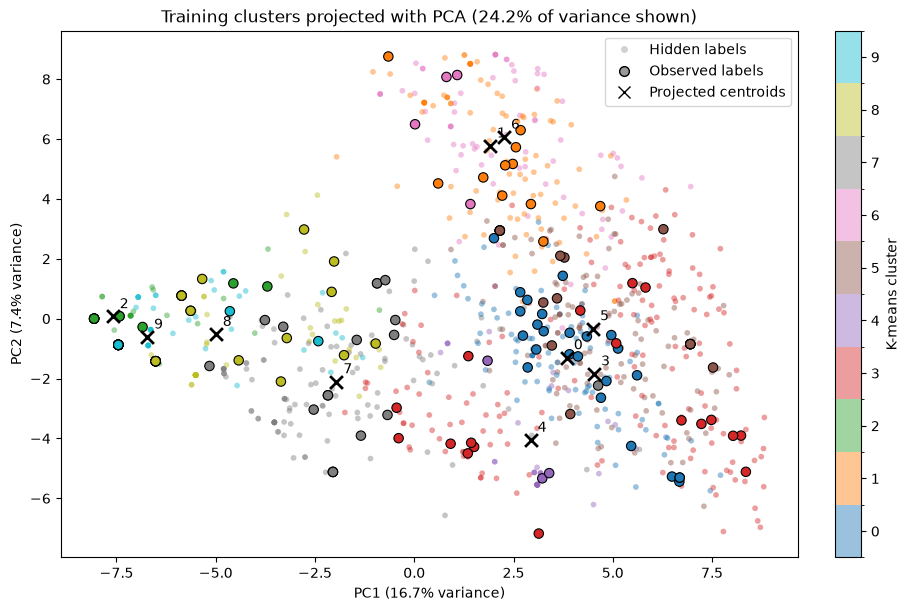

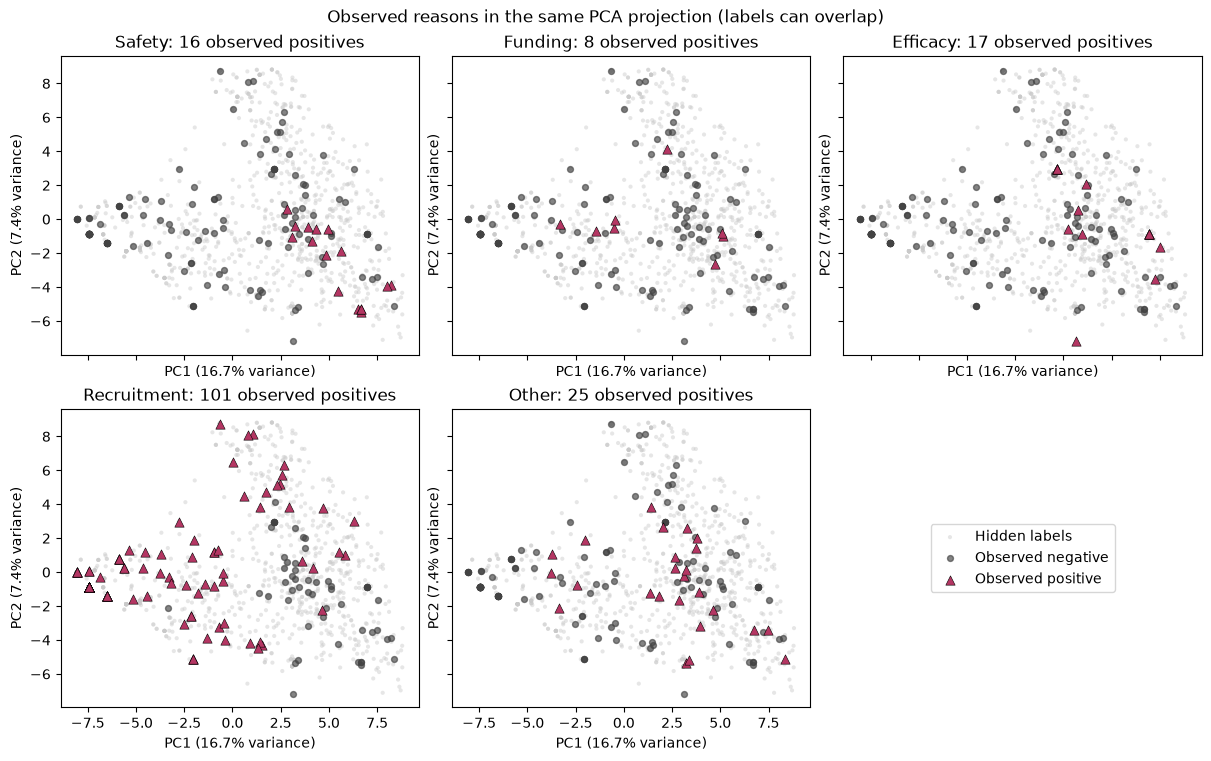

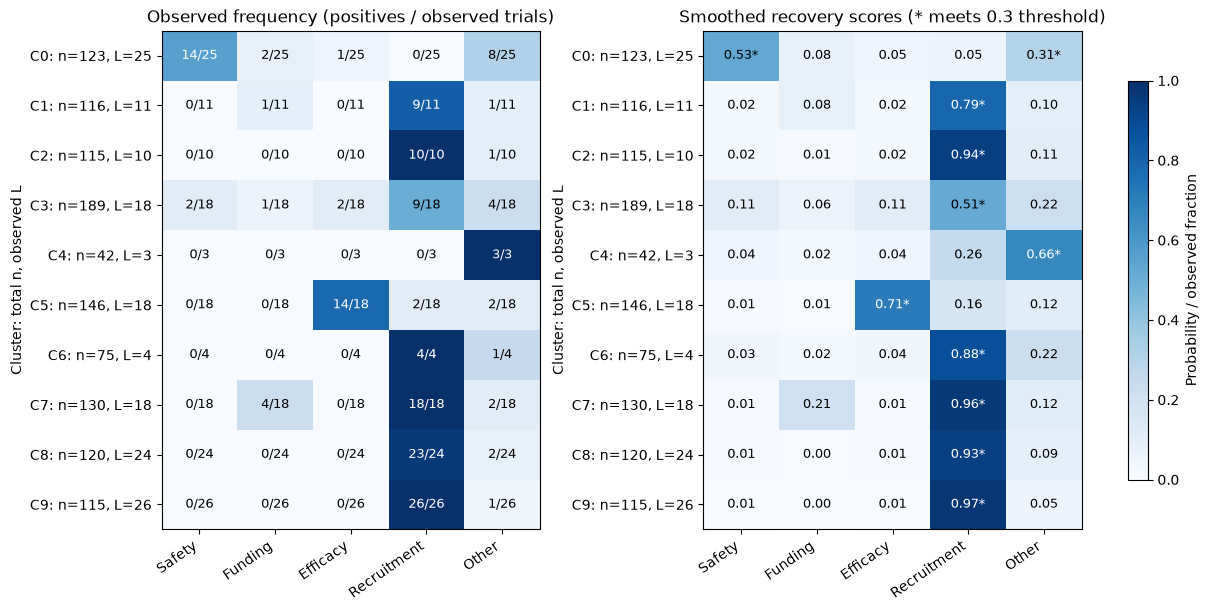

Funding cluster inspection (true labels only in observed counts):


,cluster,total,observed,hidden,observed_funding_positive,raw_funding_rate,smoothed_funding_score,funding_pseudo_positive
0,0,123,25,98,2,0.0800,0.0778,0
1,1,116,11,105,1,0.0909,0.0848,0
2,2,115,10,105,0,0.0000,0.0085,0
3,3,189,18,171,1,0.0556,0.0551,0
4,4,42,3,39,0,0.0000,0.0204,0
5,5,146,18,128,0,0.0000,0.0051,0
6,6,75,4,71,0,0.0000,0.0170,0
7,7,130,18,112,4,0.2222,0.2051,0
8,8,120,24,96,0,0.0000,0.0039,0
9,9,115,26,89,0,0.0000,0.0036,0


,cluster,ID,start_year,distance_to_centroid,label_source,observed_reasons,diseases,drugs
0,0,TR07464,2009,10.744,observed,Safety,"['diabetes mellitus, type 2']","['placebo', 'ly2599506']"
1,0,TR08610,2010,10.744,observed,Safety,"['diabetes mellitus, type 2']","['ly2599506', 'glyburide', 'placebo']"
2,0,TR01182,2002,11.072,observed,Safety,['congestive heart failure'],"['dronedarone (sr33589)', 'placebo']"
3,1,TR04307,2005,6.672,hidden,unavailable,"['anemia', 'chronic kidney disease', 'chronic ...","['placebo', 'peginesatide']"
4,1,TR06662,2008,6.904,hidden,unavailable,"['breast cancer', 'metastasis', 'sur-expressin...","['trastuzumab', 'other chemotherapy in associa..."
5,1,TR04199,2004,6.904,hidden,unavailable,['menopause'],['esterified estrogens 1.25mg and methyltestos...
6,2,TR10566,2002,1.157,observed,Recruitment,['esophageal metaplasia'],['ranitidine & pantoprazole']
7,2,TR04385,2003,1.157,hidden,unavailable,['cervical cancer'],"['carboplatin', 'docetaxel']"
8,2,TR01756,2007,1.157,hidden,unavailable,"['stage i multiple myeloma', 'stage ii multipl...","['bortezomib', 'lenalidomide', 'dexamethasone']"
9,3,TR01530,2009,7.348,hidden,unavailable,['non-small cell lung cancer'],"['carboplatin', 'paclitaxel', 'bevacizumab']"


In [8]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.colors import BoundaryNorm
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

FIGURES_DIR = PROJECT_DIR / "writeup" / "figures"
FIGURES_DIR.mkdir(exist_ok=True)
inspection_k = int(best_kmeans.k)
inspection_model = KMeans(n_clusters=inspection_k, init="k-means++", n_init=10,
                          max_iter=300, tol=1e-4, random_state=42)
with threadpool_limits(limits=1):
    inspection_clusters = inspection_model.fit_predict(X_train)
    pca_inspection = PCA(svd_solver="full")
    projected = pca_inspection.fit_transform(X_train)
projected_centroids = pca_inspection.transform(inspection_model.cluster_centers_)
explained = pca_inspection.explained_variance_ratio_
cumulative = explained.cumsum()
projection_summary = {
    "cluster_method": "kmeans", "k": inspection_k,
    "pc1_variance_fraction": float(explained[0]),
    "pc2_variance_fraction": float(explained[1]),
    "first_two_variance_fraction": float(cumulative[1]),
    "components_for_90_percent": int(np.searchsorted(cumulative, 0.90) + 1),
    "components_for_95_percent": int(np.searchsorted(cumulative, 0.95) + 1),
    "silhouette_original_space_sample_1000": float(silhouette_score(
        X_train, inspection_clusters, sample_size=1000, random_state=42))
}
(RESULTS_DIR / "pca_inspection_summary.json").write_text(json.dumps(projection_summary, indent=2) + "\n")
pd.DataFrame({"component": np.arange(1, len(explained) + 1),
              "variance_fraction": explained, "cumulative_fraction": cumulative}).to_csv(
                  RESULTS_DIR / "pca_explained_variance.csv", index=False)
coordinates = reason_train[["ID"]].copy()
coordinates["cluster"] = inspection_clusters
coordinates["observed_labels"] = label_mask
coordinates["PC1"] = projected[:, 0]
coordinates["PC2"] = projected[:, 1]
coordinates.to_csv(RESULTS_DIR / "pca_coordinates.csv", index=False)
print("PCA projection summary:", projection_summary)


def save_inspection_figure(fig, name):
    fig.savefig(FIGURES_DIR / f"{name}.png", dpi=160, bbox_inches="tight")
    fig.savefig(FIGURES_DIR / f"{name}.pdf", bbox_inches="tight")
    plt.show()
    plt.close(fig)


axis_labels = [f"PC1 ({explained[0]:.1%} variance)", f"PC2 ({explained[1]:.1%} variance)"]
fig, ax = plt.subplots(figsize=(9, 6), constrained_layout=True)
cluster_cmap = plt.get_cmap("tab10", inspection_k)
norm = BoundaryNorm(np.arange(-0.5, inspection_k + 0.5), inspection_k)
points = ax.scatter(projected[~label_mask, 0], projected[~label_mask, 1],
                    c=inspection_clusters[~label_mask], cmap=cluster_cmap, norm=norm,
                    s=17, alpha=0.45, edgecolors="none", label="Hidden labels")
ax.scatter(projected[label_mask, 0], projected[label_mask, 1],
           c=inspection_clusters[label_mask], cmap=cluster_cmap, norm=norm,
           s=46, edgecolors="black", linewidths=0.8, label="Observed labels")
ax.scatter(projected_centroids[:, 0], projected_centroids[:, 1], marker="x",
           color="black", s=85, linewidths=2, label="Projected centroids")
for cluster, (cx, cy) in enumerate(projected_centroids[:, :2]):
    ax.annotate(str(cluster), (cx, cy), xytext=(5, 6), textcoords="offset points")
fig.colorbar(points, ax=ax, ticks=range(inspection_k), label="K-means cluster")
ax.set(xlabel=axis_labels[0], ylabel=axis_labels[1],
       title=f"Training clusters projected with PCA ({cumulative[1]:.1%} of variance shown)")
ax.legend(handles=[
    Line2D([], [], marker="o", linestyle="none", markerfacecolor="0.6", markeredgecolor="none",
           markersize=5, alpha=0.45, label="Hidden labels"),
    Line2D([], [], marker="o", linestyle="none", markerfacecolor="0.6", markeredgecolor="black",
           markersize=7, label="Observed labels"),
    Line2D([], [], marker="x", linestyle="none", color="black", markersize=8,
           label="Projected centroids")], loc="best")
save_inspection_figure(fig, "part1_pca_clusters")

fig, axes = plt.subplots(2, 3, figsize=(12, 7.5), sharex=True, sharey=True,
                         constrained_layout=True)
for j, (label, ax) in enumerate(zip(labels, axes.flat)):
    positive = label_mask & reason_train[label].eq(1).to_numpy()
    negative = label_mask & reason_train[label].eq(0).to_numpy()
    ax.scatter(projected[~label_mask, 0], projected[~label_mask, 1], s=9,
               color="#c9c9c9", alpha=0.45, edgecolors="none", label="Hidden labels")
    ax.scatter(projected[negative, 0], projected[negative, 1], s=18,
               color="#434343", alpha=0.65, label="Observed negative")
    ax.scatter(projected[positive, 0], projected[positive, 1], s=45, marker="^",
               color="#b43663", edgecolors="black", linewidths=0.4, label="Observed positive")
    ax.set(title=f"{label}: {positive.sum()} observed positives", xlabel=axis_labels[0], ylabel=axis_labels[1])
handles, legend_labels = axes.flat[0].get_legend_handles_labels()
axes.flat[-1].axis("off")
axes.flat[-1].legend(handles, legend_labels, loc="center")
fig.suptitle("Observed reasons in the same PCA projection (labels can overlap)")
save_inspection_figure(fig, "part1_pca_reasons")

cluster_sizes = np.bincount(inspection_clusters, minlength=inspection_k)
known_cluster_sizes = np.bincount(inspection_clusters[label_mask], minlength=inspection_k)
reason_counts = np.zeros((inspection_k, len(labels)), dtype=int)
for cluster in range(inspection_k):
    reason_counts[cluster] = y_known[inspection_clusters[label_mask] == cluster].sum(axis=0)
raw_rates = np.divide(reason_counts, known_cluster_sizes[:, None],
                      out=np.full(reason_counts.shape, np.nan), where=known_cluster_sizes[:, None] > 0)
smoothed_rates = (reason_counts + 2.0 * prior) / (known_cluster_sizes[:, None] + 2.0)
cluster_label_decisions = threshold_reasons(smoothed_rates, float(best_kmeans.pseudo_threshold))
recovered_for_inspection = pseudo_labels[("kmeans", inspection_k, float(best_kmeans.pseudo_threshold))]
assert np.array_equal(recovered_for_inspection[~label_mask],
                      cluster_label_decisions[inspection_clusters[~label_mask]])
cluster_summary = pd.DataFrame({"cluster": range(inspection_k), "total": cluster_sizes,
                                "observed": known_cluster_sizes,
                                "hidden": cluster_sizes - known_cluster_sizes})
for name, values in [("cluster_reason_counts", reason_counts), ("cluster_reason_rates", raw_rates),
                     ("cluster_reason_smoothed", smoothed_rates)]:
    pd.DataFrame(values, columns=labels).rename_axis("cluster").to_csv(RESULTS_DIR / f"{name}.csv")
cluster_summary.to_csv(RESULTS_DIR / "cluster_sizes.csv", index=False)
fig, axes = plt.subplots(1, 2, figsize=(12, 6), constrained_layout=True)
for panel, (ax, matrix, title) in enumerate(zip(axes, [raw_rates, smoothed_rates],
        ["Observed frequency (positives / observed trials)",
         f"Smoothed recovery scores (* meets {float(best_kmeans.pseudo_threshold):g} threshold)"])):
    heatmap = ax.imshow(np.ma.masked_invalid(matrix), vmin=0, vmax=1, cmap="Blues", aspect="auto")
    ax.set_xticks(range(len(labels)), labels, rotation=35, ha="right")
    ax.set_yticks(range(inspection_k),
                  [f"C{k}: n={cluster_sizes[k]}, L={known_cluster_sizes[k]}" for k in range(inspection_k)])
    ax.set(title=title, ylabel="Cluster: total n, observed L")
    for cluster in range(inspection_k):
        for j in range(len(labels)):
            value = matrix[cluster, j]
            if panel == 0:
                annotation = f"{reason_counts[cluster, j]}/{known_cluster_sizes[cluster]}" if np.isfinite(value) else "N/A"
            else:
                annotation = f"{value:.2f}" + ("*" if value >= float(best_kmeans.pseudo_threshold) else "")
            ax.text(j, cluster, annotation, ha="center", va="center",
                    color="white" if value > 0.55 else "black", fontsize=9)
fig.colorbar(heatmap, ax=axes, label="Probability / observed fraction", shrink=0.8)
save_inspection_figure(fig, "part1_cluster_reason_heatmap")

funding_j = labels.index("Funding")
funding_inspection = cluster_summary.copy()
funding_inspection["observed_funding_positive"] = reason_counts[:, funding_j]
funding_inspection["raw_funding_rate"] = raw_rates[:, funding_j]
funding_inspection["smoothed_funding_score"] = smoothed_rates[:, funding_j]
funding_inspection["funding_pseudo_positive"] = [
    int(recovered_for_inspection[(inspection_clusters == k) & ~label_mask, funding_j].sum())
    for k in range(inspection_k)]
funding_inspection.to_csv(RESULTS_DIR / "funding_cluster_inspection.csv", index=False)
print("Funding cluster inspection (true labels only in observed counts):")
display(funding_inspection.round(4))

# Nearest examples are selected in the fitted 150-dimensional clustering space.
distance_to_centroid = np.linalg.norm(
    X_train - inspection_model.cluster_centers_[inspection_clusters], axis=1)
representatives = []
for cluster in range(inspection_k):
    members = np.flatnonzero(inspection_clusters == cluster)
    nearest = members[np.argsort(distance_to_centroid[members], kind="stable")[:3]]
    for index in nearest:
        row = reason_train.iloc[index]
        representatives.append({
            "cluster": cluster, "ID": row.ID, "start_year": row.start_year,
            "distance_to_centroid": distance_to_centroid[index],
            "label_source": "observed" if label_mask[index] else "hidden",
            "observed_reasons": " ".join(label for label in labels if row[label] == 1)
                                if label_mask[index] else "unavailable",
            "diseases": str(row.diseases_cleaned)[:160] if pd.notna(row.diseases_cleaned) else "",
            "drugs": str(row.drugs)[:100] if pd.notna(row.drugs) else ""
        })
representative_trials = pd.DataFrame(representatives)
representative_trials.to_csv(RESULTS_DIR / "cluster_representatives.csv", index=False)
display(representative_trials.round(3))

# Record the plotting dependency alongside the original environment audit.
environment["matplotlib"] = version("matplotlib")
_ = (RESULTS_DIR / "environment.json").write_text(json.dumps(environment, indent=2) + "\n")

### What the inspection shows

- **PCA is a limited view:** PC1 explains 16.7% and PC2 7.4% of training variance (24.2% together). It takes 64 components to retain 90% and 92 to retain 95%. Apparent overlap in these plots is not evidence that the original 150-dimensional clusters are inseparable. The original-space silhouette on a reproducible 1,000-trial sample is 0.1704; this is a descriptive geometry measure, not a label-recovery accuracy score.
- **Some clusters have clear observed-label associations:** cluster 0 has 14/25 Safety-positive observed trials; cluster 5 has 14/18 Efficacy-positive trials. Several other clusters are dominated by Recruitment. Cluster 0 also has 8/25 Other positives, illustrating why cluster-to-reason mapping must allow several labels.
- **Funding suppression is directly explained by the recovery rule:** all eight observed Funding positives lie in clusters 0, 1, 3, and 7 (counts 2, 1, 1, and 4). The largest raw frequency is 4/18 = 0.2222 in cluster 7; smoothing reduces it to 0.2051, below the selected 0.3 threshold. Every cluster falls below that threshold and the highest-score fallback never chooses Funding. Therefore all 1,014 recovered Funding labels are zero. This is a limitation of cluster-level probabilities plus thresholding, not proof that the embeddings lack Funding information.
- **Small labeled groups limit confidence:** clusters 4 and 6 have only 3 and 4 observed trials. Their frequencies should not be treated as precise probabilities for the larger unlabeled groups.

Possible follow-ups are label-specific recovery thresholds, local K-NN estimates, confidence filtering, or soft-label training. These have **not** been tested here. No classifier, pseudo-label, model selection, or submission was changed by this inspection.

### Controlled follow-up: lower only the Funding recovery threshold

**Predefined grid:** Funding thresholds 0.30 (control), 0.20, 0.15, and 0.10. Keep the selected K-means model, all other reason pseudo-labels, embedding-only features, pseudo-label weight 0.25, logistic-regression C=0.1, and final classifier threshold 0.5 fixed. These thresholds apply to **recovering training labels**, not thresholding validation predictions. Known training labels are never changed.

Compare validation Funding precision/recall/F1, confusion counts, sample-wise F1, macro F1, and the number of recovered Funding positives. Only four validation trials are Funding-positive, so results are exploratory. Compare the control against the original selected method as a reproducibility check. Save follow-up artifacts separately; the original submission and 70-configuration results remain unchanged. K-NN has not been implemented in this experiment.

In [9]:
from sklearn.metrics import precision_score, recall_score

FUNDING_DIR = RESULTS_DIR / "funding-threshold-experiment"
FUNDING_DIR.mkdir(exist_ok=True)
funding_thresholds = (0.30, 0.20, 0.15, 0.10)
funding_index = labels.index("Funding")
other_label_indices = [j for j in range(len(labels)) if j != funding_index]
control_y = pseudo_labels[("kmeans", inspection_k, float(best_kmeans.pseudo_threshold))]
assert best_kmeans.features == "embeddings"
assert float(best_kmeans.C) == 0.1 and float(best_kmeans.pseudo_weight) == 0.25
trial_funding_scores = smoothed_rates[inspection_clusters, funding_index]
funding_records = []
funding_candidate_predictions = {}
for threshold in funding_thresholds:
    candidate_y = control_y.copy()
    candidate_y[~label_mask, funding_index] = (trial_funding_scores[~label_mask] >= threshold).astype(int)
    assert np.array_equal(candidate_y[label_mask], y_known)
    assert np.array_equal(candidate_y[:, other_label_indices], control_y[:, other_label_indices])
    models = fit_reason_models(feature_sets["embeddings"][0], candidate_y, 0.1,
                               np.where(label_mask, 1.0, 0.25))
    prediction = threshold_reasons(reason_probabilities(models, feature_sets["embeddings"][1]))
    funding_candidate_predictions[threshold] = prediction
    actual = y_validation[:, funding_index]
    predicted = prediction[:, funding_index]
    funding_records.append({
        "funding_threshold": threshold,
        "funding_pseudo_positives": int(candidate_y[~label_mask, funding_index].sum()),
        "funding_precision": precision_score(actual, predicted, zero_division=0),
        "funding_recall": recall_score(actual, predicted, zero_division=0),
        "funding_tp": int(((actual == 1) & (predicted == 1)).sum()),
        "funding_fp": int(((actual == 0) & (predicted == 1)).sum()),
        "funding_fn": int(((actual == 1) & (predicted == 0)).sum()),
        **reason_metrics(y_validation, prediction)
    })
    output = reason_val[["ID"]].copy()
    output[labels] = prediction
    output.to_csv(FUNDING_DIR / f"validation_threshold_{threshold:.2f}.csv", index=False)
    recovered_output = reason_train[["ID"]].copy()
    recovered_output["Funding"] = candidate_y[:, funding_index]
    recovered_output["label_source"] = np.where(label_mask, "observed_train", "pseudo_train")
    recovered_output.to_csv(FUNDING_DIR / f"training_funding_threshold_{threshold:.2f}.csv", index=False)

funding_results = pd.DataFrame(funding_records)
assert np.isclose(funding_results.iloc[0].sample_f1, best_kmeans.sample_f1)
assert np.isclose(funding_results.iloc[0]["Funding"], best_kmeans["Funding"])
funding_results.to_csv(FUNDING_DIR / "results.csv", index=False)
display(funding_results[["funding_threshold", "funding_pseudo_positives", "funding_precision",
                         "funding_recall", "Funding", "funding_tp", "funding_fp", "funding_fn",
                         "sample_f1", "macro_f1"]].round(4))
funding_best = funding_results.sort_values(["sample_f1", "macro_f1"], ascending=False,
                                          kind="stable").iloc[0]
print("Best follow-up threshold by sample-wise F1, then macro F1:", funding_best.funding_threshold)
print("Original submission and selected-model artifacts remain unchanged.")


,funding_threshold,funding_pseudo_positives,funding_precision,funding_recall,Funding,funding_tp,funding_fp,funding_fn,sample_f1,macro_f1
0,0.30,0,1.00,0.25,0.40,1,0,3,0.8547,0.6923
1,0.20,112,0.25,0.25,0.25,1,3,3,0.8419,0.6623
2,0.15,112,0.25,0.25,0.25,1,3,3,0.8419,0.6623
3,0.10,112,0.25,0.25,0.25,1,3,3,0.8419,0.6623


Best follow-up threshold by sample-wise F1, then macro F1: 0.3
Original submission and selected-model artifacts remain unchanged.


### Funding threshold experiment: interpretation

Lowering the recovery threshold from 0.30 to 0.20, 0.15, or 0.10 assigns Funding to the same 112 hidden-label trials in cluster 7. No other cluster's smoothed Funding score reaches 0.10, so these three candidates are identical. All observed labels and other pseudo-labels remain unchanged.

The control classifier identifies 1 of 4 Funding-positive validation trials and has no Funding false positives (precision 1.0, recall 0.25, F1 0.40). Each lower-threshold classifier still identifies only 1 of the 4, but adds 3 false positives (precision 0.25, recall 0.25, F1 0.25). Sample-wise F1 falls from 0.8547 to 0.8419; macro F1 falls from 0.6923 to 0.6623. We therefore retain threshold 0.30 and the original model/submission. This result applies to this fixed clustering, representation, and weighting setting; only four Funding positives limit the strength of the conclusion.

This illustrates a risk of cluster-wide recovery: a lower threshold promotes an entire group, rather than identifying which members plausibly have Funding reasons. A local neighbor-based estimate is a motivated follow-up, not a proven improvement. K-NN has not been tested here.

### Local label recovery with K-NN, and a K-means/K-NN hybrid

**Predefined grid:** K = 3, 5, 9, or 15 labeled neighbors, using uniform voting or inverse-distance weighting. Neighbors are searched among the **157 observed training trials only**, in the original 150-dimensional standardized embedding space. Unlabeled trials never become reference neighbors, and validation trials are never used as neighbors or for fitting.

Compare three uses of the same neighbor settings:

- **Direct K-NN (supervised control):** estimate validation reason probabilities directly from the labeled neighbors. This alone does not meet the unsupervised-method requirement.
- **K-NN recovery:** estimate missing training labels from neighbors, then fit the same weighted logistic regressions as before. This is a comparison to cluster-based recovery, not a substitute for the required unsupervised experiment.
- **K-means/K-NN hybrid:** average each reason's K-NN score and its smoothed cluster score equally, recover missing labels, and fit weighted logistic regressions. This explicitly retains unsupervised clustering in the recovery process.

For both recovery methods, hold the pseudo-label threshold at 0.3, pseudo-label weight at 0.25, classifier C at 0.1, and embedding-only features fixed. Preserve observed labels; final predictions use 0.5 with the existing highest-score fallback. Include a labeled-only logistic-regression control with C=0.1 to isolate augmentation effects. The original C=1 starter and selected K-means results remain reference scores. No new feature, threshold, C, or blend-weight search is performed.

Select the best augmented candidate by validation sample-wise F1, then macro F1, with stable grid order for remaining ties. Export its test predictions separately without overwriting the existing selected-model artifacts or original submission. Neighbor vote fractions and hybrid scores are estimates, not calibrated probabilities. This is further exploratory reuse of the small validation set.

In [10]:
from sklearn.neighbors import KNeighborsClassifier

KNN_DIR = RESULTS_DIR / "knn-experiment"
KNN_DIR.mkdir(exist_ok=True)
knn_records = []
knn_recovered_candidates = {}
knn_augmented_models = {}
knn_validation_predictions = {}


def neighbor_reason_scores(model, query):
    probabilities = model.predict_proba(query)
    return np.column_stack([
        probability[:, np.flatnonzero(classes == 1)[0]]
        for probability, classes in zip(probabilities, model.classes_)
    ])


def knn_record(method, k, weighting, prediction, augmented=None):
    actual = y_validation[:, labels.index("Funding")]
    predicted = prediction[:, labels.index("Funding")]
    record = {
        "method": method, "neighbors": k, "neighbor_weighting": weighting,
        "funding_precision": precision_score(actual, predicted, zero_division=0),
        "funding_recall": recall_score(actual, predicted, zero_division=0),
        "funding_tp": int(((actual == 1) & (predicted == 1)).sum()),
        "funding_fp": int(((actual == 0) & (predicted == 1)).sum()),
        "funding_fn": int(((actual == 1) & (predicted == 0)).sum()),
        **reason_metrics(y_validation, prediction)
    }
    for j, label in enumerate(labels):
        record[f"pseudo_{label}"] = int(augmented[~label_mask, j].sum()) if augmented is not None else 0
    return record


matched_control_models = fit_reason_models(feature_sets["embeddings"][0][label_mask], y_known, 0.1)
matched_control_prediction = threshold_reasons(
    reason_probabilities(matched_control_models, feature_sets["embeddings"][1]))
knn_records.append(knn_record("supervised_lr_C0.1", 0, "none", matched_control_prediction))
cluster_scores_for_hidden = smoothed_rates[inspection_clusters[~label_mask]]
for k in (3, 5, 9, 15):
    for weighting in ("uniform", "distance"):
        neighbors = KNeighborsClassifier(n_neighbors=k, weights=weighting,
                                         metric="euclidean", algorithm="brute", n_jobs=1)
        neighbors.fit(X_train[label_mask], y_known)
        with threadpool_limits(limits=1):
            hidden_neighbor_scores = neighbor_reason_scores(neighbors, X_train[~label_mask])
            direct_val_prediction = threshold_reasons(neighbor_reason_scores(neighbors, X_val))
        knn_records.append(knn_record("direct_knn", k, weighting, direct_val_prediction))
        knn_validation_predictions[("direct_knn", k, weighting)] = direct_val_prediction
        for method in ("knn_recovery", "kmeans_knn_hybrid"):
            recovery_scores = hidden_neighbor_scores if method == "knn_recovery" else (
                0.5 * hidden_neighbor_scores + 0.5 * cluster_scores_for_hidden)
            augmented = np.empty((len(reason_train), len(labels)), dtype=int)
            augmented[label_mask] = y_known
            augmented[~label_mask] = threshold_reasons(recovery_scores, 0.3)
            assert np.array_equal(augmented[label_mask], y_known)
            assert np.isin(augmented, [0, 1]).all()
            models = fit_reason_models(feature_sets["embeddings"][0], augmented, 0.1,
                                       np.where(label_mask, 1.0, 0.25))
            prediction = threshold_reasons(reason_probabilities(models, feature_sets["embeddings"][1]))
            key = (method, k, weighting)
            knn_records.append(knn_record(method, k, weighting, prediction, augmented))
            knn_recovered_candidates[key] = augmented
            knn_augmented_models[key] = models
            knn_validation_predictions[key] = prediction

knn_results = pd.DataFrame(knn_records).sort_values(["sample_f1", "macro_f1"],
                                                  ascending=False, kind="stable").reset_index(drop=True)
knn_results.to_csv(KNN_DIR / "results.csv", index=False)
for (method, k, weighting), prediction in knn_validation_predictions.items():
    output = reason_val[["ID"]].copy()
    output[labels] = prediction
    output.to_csv(KNN_DIR / f"validation_{method}_k{k}_{weighting}.csv", index=False)
print("Best configuration within each method:")
display(knn_results.groupby("method", sort=False).head(1)[
    ["method", "neighbors", "neighbor_weighting", "sample_f1", "macro_f1", "Funding",
     "funding_precision", "funding_recall", "funding_tp", "funding_fp", "pseudo_Funding"]].round(4))
print("All 25 predefined follow-up configurations:")
display(knn_results[["method", "neighbors", "neighbor_weighting", "sample_f1", "macro_f1", "Funding"]].round(4))

best_knn_augmented = knn_results[knn_results.method.isin(["knn_recovery", "kmeans_knn_hybrid"])].iloc[0]
knn_key = (best_knn_augmented.method, int(best_knn_augmented.neighbors), best_knn_augmented.neighbor_weighting)
best_knn_recovered = reason_train[["ID"]].copy()
best_knn_recovered[labels] = knn_recovered_candidates[knn_key]
best_knn_recovered["label_source"] = np.where(label_mask, "observed_train", "pseudo_train")
best_knn_recovered.to_csv(KNN_DIR / "best_augmented_training_labels.csv", index=False)
best_knn_test_pred = threshold_reasons(reason_probabilities(knn_augmented_models[knn_key], feature_sets["embeddings"][2]))
knn_test_output = reason_test[["ID"]].copy()
knn_test_output["Predicted"] = [" ".join(label for label, value in zip(labels, row) if value)
                                for row in best_knn_test_pred]
assert knn_test_output.ID.equals(reason_test.ID) and knn_test_output.Predicted.str.len().gt(0).all()
knn_test_output.to_csv(KNN_DIR / "best_augmented_candidate_submission.csv", index=False)
knn_selection = {"method": knn_key[0], "neighbors": knn_key[1], "neighbor_weighting": knn_key[2],
                 "sample_f1": float(best_knn_augmented.sample_f1),
                 "macro_f1": float(best_knn_augmented.macro_f1),
                 "configurations": len(knn_results), "pseudo_threshold": 0.3,
                 "pseudo_weight": 0.25, "C": 0.1, "features": "embeddings",
                 "cluster_score_weight": 0.5 if knn_key[0] == "kmeans_knn_hybrid" else 0.0,
                 "overwrites_original_selection": False}
_ = (KNN_DIR / "best_augmented_candidate.json").write_text(json.dumps(knn_selection, indent=2) + "\n")
print("Best augmented candidate:", knn_selection)
print("Reference sample-wise F1: starter =", baseline.sample_f1, "; selected K-means =", best_kmeans.sample_f1)

# Regenerate the follow-up report table from measured results.
knn_table_methods = ["direct_knn", "knn_recovery", "kmeans_knn_hybrid"]
knn_table_best = [knn_results[knn_results.method == method].iloc[0] for method in knn_table_methods]
knn_table_rows = [r"\begin{tabular}{lrrr}", r"\toprule",
                  "Metric & Direct KNN & KNN+LR & Hybrid " + chr(92) * 2, r"\midrule"]
for metric, title in [("sample_f1", "Sample F1"), ("macro_f1", "Macro F1"), *[(label, label) for label in labels]]:
    knn_table_rows.append(title + " & " + " & ".join(f"{row[metric]:.4f}" for row in knn_table_best) + " " + chr(92) * 2)
knn_table_rows.extend([r"\bottomrule", r"\end{tabular}"])
_ = (PROJECT_DIR / "writeup" / "part1_knn_results.tex").write_text("\n".join(knn_table_rows) + "\n")


Best configuration within each method:


,method,neighbors,neighbor_weighting,sample_f1,macro_f1,Funding,funding_precision,funding_recall,funding_tp,funding_fp,pseudo_Funding
0,kmeans_knn_hybrid,3,uniform,0.8868,0.7792,0.6667,1.000,0.50,2,0,16
1,knn_recovery,3,uniform,0.8803,0.7873,0.6667,1.000,0.50,2,0,45
4,direct_knn,3,distance,0.8632,0.6133,0.0000,0.000,0.00,0,0,0
8,supervised_lr_C0.1,0,none,0.8534,0.6463,0.1667,0.125,0.25,1,7,0


All 25 predefined follow-up configurations:


,method,neighbors,neighbor_weighting,sample_f1,macro_f1,Funding
0,kmeans_knn_hybrid,3,uniform,0.8868,0.7792,0.6667
1,knn_recovery,3,uniform,0.8803,0.7873,0.6667
2,knn_recovery,3,distance,0.8803,0.7873,0.6667
3,kmeans_knn_hybrid,3,distance,0.8739,0.7083,0.4000
4,direct_knn,3,distance,0.8632,0.6133,0.0000
5,kmeans_knn_hybrid,5,uniform,0.8568,0.6660,0.4000
6,knn_recovery,9,distance,0.8568,0.7210,0.6667
7,kmeans_knn_hybrid,5,distance,0.8568,0.6597,0.4000
8,supervised_lr_C0.1,0,none,0.8534,0.6463,0.1667
9,knn_recovery,15,distance,0.8504,0.6776,0.4000


Best augmented candidate: {'method': 'kmeans_knn_hybrid', 'neighbors': 3, 'neighbor_weighting': 'uniform', 'sample_f1': 0.8867521367521366, 'macro_f1': 0.7792343604108309, 'configurations': 25, 'pseudo_threshold': 0.3, 'pseudo_weight': 0.25, 'C': 0.1, 'features': 'embeddings', 'cluster_score_weight': 0.5, 'overwrites_original_selection': False}
Reference sample-wise F1: starter = 0.8653846153846155 ; selected K-means = 0.8547008547008546


### K-NN follow-up: results and interpretation

The best local-recovery setting uses **3 uniformly weighted labeled neighbors**. Its augmented logistic regression scores sample-wise F1 0.8803 and macro F1 0.7873. Equal blending with the original K-means cluster scores improves sample-wise F1 to **0.8868**, with macro F1 **0.7792**. Both exceed the original K-means result (0.8547 / 0.6923); the hybrid also exceeds the starter (0.8654 / 0.7067) and the earlier strongest supervised control (0.8782 / 0.6990) on these validation data. The matched labeled-only logistic-regression control at C=0.1 scores 0.8534 / 0.6463.

The hybrid produces **16 Funding pseudo-positives**, while K-NN-only recovery produces 45; the lowered cluster threshold previously produced 112. Both best augmented local methods identify 2 of the 4 Funding-positive validation trials, with no Funding false positives (precision 1.0, recall 0.5, F1 0.6667). Direct K-NN performs differently: its best configuration uses 3 distance-weighted neighbors and scores sample F1 0.8632, but identifies no Funding-positive validation trials.

This shows that local recovery can preserve rare-label information without promoting an entire cluster in this experiment. It does not prove general superiority: 78 validation trials, four Funding positives, and repeated selection across 99 total evaluated configurations (70 initial, 4 Funding thresholds, 25 neighbor controls/candidates) introduce selection uncertainty. K-NN-only recovery has higher macro F1 than the hybrid; the hybrid is chosen among the new augmented candidates because sample-wise F1 is the stated primary metric.

The original submission/model artifacts are frozen for comparison. The new hybrid candidate, recovered labels, all validation predictions, and settings are saved under `part1-results/knn-experiment/`. Clustering remains part of the hybrid, satisfying the unsupervised-method requirement; direct K-NN by itself would not. No test score or Kaggle submission is claimed.

### Save Part 1 predictions

Save the selected semi-supervised model's test predictions as `ID,Predicted`. Reason names are space-separated. These are local files; this notebook does not upload them to Kaggle.

In [11]:
test_pred = selected_test_pred
predicted_reasons = []

for row in test_pred:
    names = [label for label, value in zip(labels, row) if value == 1]
    predicted_reasons.append(" ".join(names))

part1_submission = reason_test[["ID"]].copy()
part1_submission["Predicted"] = predicted_reasons
part1_submission.to_csv(PROJECT_DIR / "part1_submission.csv", index=False)
part1_submission.head()

assert part1_submission.ID.equals(reason_test.ID)
assert part1_submission.Predicted.str.len().gt(0).all()
assert len(part1_submission) == 312

## Part 2: Predict trial success, inspect errors, and improve the classifier

**Objective:** independently predict whether each Phase I, II, or III trial met its primary endpoint (`label=1`). A completed trial may still fail. Fit a separate classifier per phase, using the supplied outcome training/validation split. Test rows are later-year trials; provide probabilities, not binary labels, for Kaggle log loss.

**Connection to homework:** retain the original bag-of-words logistic regression baseline; test TF-IDF/short phrases and regularization from HW2, and a Naive Bayes comparison related to HW3. Keep structured ICD identifiers intact. Use Part 1 reasons only afterward to group unsuccessful validation trials and compare error rates. Never feed reason embeddings, reason labels, IDs, or validation outcomes into classifier fitting.

Selection minimizes validation log loss separately per phase because the competition evaluates success probabilities and averages over equal-size phase test sets. Also report F1 at fixed threshold 0.5, ROC-AUC, and average precision (PR-AUC). No F1 threshold tuning is performed.

In [12]:
import re
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.naive_bayes import MultinomialNB
from sklearn.calibration import CalibratedClassifierCV
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import brier_score_loss
from sklearn.feature_extraction.text import TfidfVectorizer

PART2_RESULTS = PROJECT_DIR / "part2-results"
PART2_RESULTS.mkdir(exist_ok=True)
PHASES = ["I", "II", "III"]
REASON_LABELS = ["Safety", "Funding", "Efficacy", "Recruitment", "Other"]
OUTCOME_RAW_FEATURES = ["criteria", "diseases_cleaned", "drugs", "icdcodes",
                        "drug_targets", "drug_actions", "drug_pathways", "start_year"]
assert not (set(OUTCOME_RAW_FEATURES) & set(REASON_LABELS + ["ID", "trial_id", "label"]))
assert not any(name.startswith("emb_") for name in OUTCOME_RAW_FEATURES)
for frame in (outcome_train, outcome_val, outcome_test):
    assert frame.ID.is_unique
    assert not frame.duplicated(["trial_id", "phase"]).any()
    assert set(frame.phase) == set(PHASES)
for left, right in [(outcome_train, outcome_val), (outcome_train, outcome_test), (outcome_val, outcome_test)]:
    assert set(left.trial_id).isdisjoint(right.trial_id)
assert outcome_train.label.isin([0, 1]).all() and outcome_val.label.isin([0, 1]).all()


def normalize_clinical_text(value):
    text = "" if pd.isna(value) else str(value).lower()
    text = re.sub(r"[•‣◦⁃∙]", " ", text)
    text = re.sub(r"[^\w\s'-]", " ", text)
    return re.sub(r"\s+", " ", text).strip()


def structured_code_text(row):
    raw = "" if pd.isna(row["icdcodes"]) else str(row["icdcodes"])
    # Nested list formatting is ignored, but an ICD code such as E11.9 stays one token.
    codes = re.findall(r"[A-Za-z][0-9][A-Za-z0-9]*(?:[.-][A-Za-z0-9]+)*", raw)
    return " ".join(sorted({"icd_" + re.sub(r"[^a-z0-9]", "", value.lower()) for value in codes}))


def drug_knowledge_text(row):
    tokens = []
    for field, prefix in [("drug_targets", "target"), ("drug_actions", "action"), ("drug_pathways", "pathway")]:
        if pd.notna(row[field]):
            for value in str(row[field]).split(";"):
                token = re.sub(r"[^a-z0-9]+", "_", value.lower()).strip("_")
                if token:
                    tokens.append(prefix + "_" + token)
    if not tokens:
        tokens.append("knowledge_missing")
    return " ".join(sorted(set(tokens)))


def outcome_feature_frame(frame):
    # An explicit allowlist prevents audit columns/IDs/reasons entering a model.
    raw = frame[OUTCOME_RAW_FEATURES].copy()
    result = pd.DataFrame(index=frame.index)
    result["baseline_text"] = raw[["criteria", "diseases_cleaned", "drugs", "icdcodes"]].fillna("").agg(" ".join, axis=1)
    result["criteria_text"] = raw.criteria.map(normalize_clinical_text)
    result["context_text"] = raw[["diseases_cleaned", "drugs"]].fillna("").agg(" ".join, axis=1).map(normalize_clinical_text)
    result["code_text"] = raw.apply(structured_code_text, axis=1)
    result["knowledge_text"] = raw.apply(drug_knowledge_text, axis=1)
    result["start_year"] = pd.to_numeric(raw.start_year, errors="coerce")
    return result


outcome_inputs = {name: outcome_feature_frame(frame) for name, frame in
                  [("train", outcome_train), ("validation", outcome_val), ("test", outcome_test)]}
assert structured_code_text(pd.Series({"icdcodes": "[\"['E11.9', 'F41.1']\"]"})) == "icd_e119 icd_f411"
assert "pathway_r_hsa_123" in drug_knowledge_text(pd.Series({
    "drug_targets": np.nan, "drug_actions": np.nan, "drug_pathways": "R-HSA-123"}))


def outcome_transformer(feature_set):
    if feature_set == "starter_bow":
        blocks = [("bow", CountVectorizer(binary=True, min_df=3, max_features=20000), "baseline_text")]
    else:
        blocks = [("criteria", TfidfVectorizer(min_df=3, max_features=10000,
                    ngram_range=(1, 2), sublinear_tf=True,
                    token_pattern=r"(?u)\b\w+(?:[-']\w+)*\b"), "criteria_text")]
        if feature_set in ("clinical_tfidf", "clinical_knowledge_year"):
            blocks.extend([
                ("context", TfidfVectorizer(min_df=3, max_features=3000, sublinear_tf=True,
                    token_pattern=r"(?u)\b\w+(?:[-']\w+)*\b"), "context_text"),
                ("icd", TfidfVectorizer(min_df=3, max_features=1500,
                    tokenizer=str.split, token_pattern=None, lowercase=False), "code_text")])
        if feature_set == "clinical_knowledge_year":
            blocks.extend([
                ("knowledge", TfidfVectorizer(min_df=3, max_features=2000,
                    tokenizer=str.split, token_pattern=None, lowercase=False), "knowledge_text"),
                ("year", Pipeline([("impute", SimpleImputer(strategy="median", add_indicator=True)),
                                    ("scale", StandardScaler())]), ["start_year"])])
    return ColumnTransformer(blocks, remainder="drop", sparse_threshold=1.0)


def outcome_pipeline(feature_set, family="lr", C=1.0, class_weight=None, alpha=1.0):
    if family == "lr":
        classifier = LogisticRegression(C=C, class_weight=class_weight, max_iter=1500,
                                         solver="liblinear", random_state=42)
    else:
        assert family == "multinomial_nb" and feature_set != "clinical_knowledge_year"
        classifier = MultinomialNB(alpha=alpha)
    return Pipeline([("features", outcome_transformer(feature_set)), ("classifier", classifier)])


def outcome_metrics(truth, probability):
    predicted = (probability >= 0.5).astype(int)
    truth = np.asarray(truth)
    return {"F1": f1_score(truth, predicted, zero_division=0),
            "ROC_AUC": roc_auc_score(truth, probability),
            "AP": average_precision_score(truth, probability),
            "log_loss": log_loss(truth, probability),
            "brier": brier_score_loss(truth, probability),
            "false_success_rate": float(predicted[truth == 0].mean()),
            "confident_wrong_fraction": float(np.mean(((truth == 0) & (probability >= 0.9)) |
                                                       ((truth == 1) & (probability <= 0.1))))}


split_summary = []
for name, frame in [("train", outcome_train), ("validation", outcome_val), ("test", outcome_test)]:
    for phase in PHASES:
        section = frame[frame.phase == phase]
        split_summary.append({"split": name, "phase": phase, "rows": len(section),
                              "year_min": section.start_year.min(), "year_max": section.start_year.max(),
                              "year_missing": int(section.start_year.isna().sum()),
                              "success_rate": section.label.mean() if "label" in section else np.nan})
split_summary = pd.DataFrame(split_summary)
split_summary.to_csv(PART2_RESULTS / "split_summary.csv", index=False)
display(split_summary.round(4))

,split,phase,rows,year_min,year_max,year_missing,success_rate
0,train,I,1012,1995.0,2013.0,3,0.5662
1,train,II,3950,1995.0,2013.0,10,0.4770
2,train,III,3075,1993.0,2013.0,8,0.6533
3,validation,I,149,1999.0,2013.0,2,0.5705
4,validation,II,501,1995.0,2013.0,3,0.4711
5,validation,III,363,1995.0,2013.0,1,0.6612
6,test,I,500,2014.0,2020.0,0,NaN
7,test,II,500,2014.0,2021.0,0,NaN
8,test,III,500,2014.0,2020.0,0,NaN


### Original baseline and reason-based error analysis

Reproduce the starter: binary bag of words from criteria/diseases/drugs/ICD codes, separate C=1 logistic regression for each phase. Use training data only for vocabulary and coefficients. Match **unsuccessful validation trials only** to the latest Part 1 hybrid candidate, using `trial_id` and Part 1 `ID`.

Use observed reasons when provided (visible Part 1 training rows or Part 1 validation); use hybrid pseudo-labels for masked training rows and hybrid predictions for Part 1 test rows. Unmatched trials form the separate **no recorded stopping reason** group. This does not mean no reason exists. Multi-label trials may appear in several categories, but a trial is counted only once per category within a phase. Preserve detailed provenance and mark empty groups with undefined (NaN / N/A) rates.

In [13]:
part2_candidates = {}
part2_specs = {}
part2_records = []
part2_val_probabilities = {}


def evaluate_outcome_candidate(phase, candidate_id, estimator, spec):
    train_index = outcome_train.index[outcome_train.phase == phase]
    validation_index = outcome_val.index[outcome_val.phase == phase]
    with threadpool_limits(limits=1), warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always", ConvergenceWarning)
        estimator.fit(outcome_inputs["train"].loc[train_index], outcome_train.loc[train_index, "label"])
        probability = estimator.predict_proba(outcome_inputs["validation"].loc[validation_index])[:, 1]
    assert np.isfinite(probability).all() and ((0 <= probability) & (probability <= 1)).all()
    key = (phase, candidate_id)
    part2_candidates[key] = estimator
    part2_specs[key] = spec
    part2_val_probabilities[key] = probability
    record = {"phase": phase, "candidate": candidate_id, **spec,
              "convergence_warnings": sum(issubclass(w.category, ConvergenceWarning) for w in caught),
              **outcome_metrics(outcome_val.loc[validation_index, "label"], probability)}
    part2_records.append(record)
    return record


for phase in PHASES:
    evaluate_outcome_candidate(phase, "starter", outcome_pipeline("starter_bow"),
                               {"family": "lr", "features": "starter_bow", "C": 1.0,
                                "class_weight": "none", "alpha": np.nan, "calibration": "none"})
baseline_outcome_metrics = pd.DataFrame(part2_records)
baseline_outcome_metrics.to_csv(PART2_RESULTS / "baseline_metrics.csv", index=False)
baseline_outcome_validation = outcome_val[["ID", "trial_id", "phase", "label"]].copy()
for phase in PHASES:
    index = baseline_outcome_validation.index[baseline_outcome_validation.phase == phase]
    probability = part2_val_probabilities[(phase, "starter")]
    baseline_outcome_validation.loc[index, "probability"] = probability
    baseline_outcome_validation.loc[index, "prediction"] = (probability >= 0.5).astype(int)
baseline_outcome_validation.to_csv(PART2_RESULTS / "baseline_validation_predictions.csv", index=False)
display(baseline_outcome_metrics[["phase", "F1", "ROC_AUC", "AP", "log_loss", "false_success_rate", "confident_wrong_fraction"]].round(4))

part1_candidate_dir = RESULTS_DIR / "knn-experiment"
part1_lineage = json.loads((part1_candidate_dir / "best_augmented_candidate.json").read_text())
reason_train_hybrid = pd.read_csv(part1_candidate_dir / "best_augmented_training_labels.csv")
reason_validation_observed = reason_val[["ID", *REASON_LABELS]].copy()
reason_validation_observed["label_source"] = "observed_validation"
reason_test_hybrid = pd.read_csv(part1_candidate_dir / "best_augmented_candidate_submission.csv")
for reason in REASON_LABELS:
    reason_test_hybrid[reason] = reason_test_hybrid.Predicted.str.split().map(lambda values: int(reason in values))
reason_test_hybrid["label_source"] = "predicted_part1_test"
part2_reason_lookup = pd.concat([
    reason_train_hybrid, reason_validation_observed,
    reason_test_hybrid[["ID", *REASON_LABELS, "label_source"]]], ignore_index=True)
assert part2_reason_lookup.ID.is_unique and len(part2_reason_lookup) == 1561
assert part2_reason_lookup[REASON_LABELS].isin([0, 1]).all().all()
assert part2_reason_lookup[REASON_LABELS].sum(axis=1).gt(0).all()
part2_reason_lookup.to_csv(PART2_RESULTS / "part1_hybrid_reason_lookup.csv", index=False)
_ = (PART2_RESULTS / "part1_reason_lineage.json").write_text(json.dumps(part1_lineage, indent=2) + "\n")


def unsuccessful_reason_audit(predictions):
    failed = predictions[predictions.label == 0].copy()
    assert not failed.duplicated(["trial_id", "phase"]).any()
    failed = failed.merge(part2_reason_lookup.rename(columns={"ID": "trial_id"}), on="trial_id",
                          how="left", validate="many_to_one", indicator="reason_match")
    failed["label_source"] = failed.label_source.fillna("no_recorded_stopping_reason")
    failed["reason_provenance"] = np.select([
        failed.label_source.isin(["observed_train", "observed_validation"]),
        failed.label_source.isin(["pseudo_train", "predicted_part1_test"])],
        ["observed", "predicted"], default="unmatched")
    rows = []
    for phase in PHASES:
        phase_rows = failed[failed.phase == phase]
        for reason in [*REASON_LABELS, "No recorded reason"]:
            group = phase_rows[phase_rows[reason] == 1] if reason in REASON_LABELS else phase_rows[phase_rows.reason_match == "left_only"]
            counts = group.reason_provenance.value_counts()
            errors = int(group.prediction.sum())
            rows.append({"phase": phase, "reason": reason, "n": len(group),
                         "false_successes": errors,
                         "false_success_rate": errors / len(group) if len(group) else np.nan,
                         "observed_reason_n": int(counts.get("observed", 0)),
                         "predicted_reason_n": int(counts.get("predicted", 0)),
                         "unmatched_n": int(counts.get("unmatched", 0))})
    return failed, pd.DataFrame(rows)


baseline_failed_audit, baseline_reason_errors = unsuccessful_reason_audit(baseline_outcome_validation)
baseline_failed_audit.to_csv(PART2_RESULTS / "baseline_failed_trial_audit.csv", index=False)
baseline_reason_errors.to_csv(PART2_RESULTS / "baseline_reason_errors.csv", index=False)
display(baseline_reason_errors.round(4))
print("Failed-trial provenance by phase:")
display(baseline_failed_audit.groupby(["phase", "label_source"]).size().unstack(fill_value=0))

,phase,F1,ROC_AUC,AP,log_loss,false_success_rate,confident_wrong_fraction
0,I,0.7006,0.7029,0.7543,0.8791,0.4688,0.1342
1,II,0.6141,0.6633,0.6383,1.0603,0.3698,0.1637
2,III,0.7739,0.7049,0.8152,0.8808,0.4959,0.1295


,phase,reason,n,false_successes,false_success_rate,observed_reason_n,predicted_reason_n,unmatched_n
0,I,Safety,8,3,0.3750,1,7,0
1,I,Funding,3,2,0.6667,1,2,0
2,I,Efficacy,4,2,0.5000,0,4,0
3,I,Recruitment,24,10,0.4167,2,22,0
4,I,Other,3,2,0.6667,0,3,0
5,I,No recorded reason,28,16,0.5714,0,0,28
6,II,Safety,11,6,0.5455,1,10,0
7,II,Funding,4,1,0.2500,1,3,0
8,II,Efficacy,15,6,0.4000,0,15,0
9,II,Recruitment,93,33,0.3548,12,81,0


Failed-trial provenance by phase:


label_source,no_recorded_stopping_reason,observed_train,observed_validation,predicted_part1_test,pseudo_train
phase,,,,,
I,28,2,2,7,25
II,144,13,3,27,78
III,82,6,1,6,28


### Improve the model based on the baseline errors

The baseline predicts success for 6/8 Phase III unsuccessful trials with Efficacy reasons and makes substantial errors in unmatched groups. These are overlapping, often predicted, small groups; they do not establish medical causes. High validation log loss also motivates reducing overconfident probability errors.

Test a compact predefined grid:

- **Representations:** criteria TF-IDF; separate criteria/context/ICD TF-IDF blocks; those blocks plus structured targets/actions/pathways and imputed, standardized start year. Separate blocks keep long criteria text from setting the only normalization scale. Preserve negations, numbers, in-word hyphens, and structured identifiers. Learn vocabularies, IDF, imputation, and scaling only from training data.
- **Logistic regression:** C = 0.1, 1, or 10, with no class balancing or training-label-based balanced class weights. Balancing may reduce false-success errors but can change recall and probability quality.
- **Multinomial Naive Bayes:** alpha = 0.1, 1, or 10 on the two nonnegative TF-IDF representations (not standardized year features).
- **Calibration:** train-only three-fold sigmoid calibration of the starter and the best uncalibrated TF-IDF logistic-regression candidate. Entire feature/model pipelines are refitted inside folds. Fold splits are stratified with shuffle and seed 42; each trial occurs once within a phase, so no trial crosses folds within a phase model. Validation is only for selection, never fitting or calibration.

Select each phase's modified candidate by validation log loss (stable evaluation order breaks ties). Retain the baseline as a fallback if no candidate improves it. F1 stays at 0.5; analyze all reason groups again using identical reasons and cohort membership. Reasons never enter inputs, weights, or calibration.

In [14]:
for phase in PHASES:
    for feature_set in ("criteria_tfidf", "clinical_tfidf", "clinical_knowledge_year"):
        for c in (0.1, 1.0, 10.0):
            for balancing in (None, "balanced"):
                candidate = f"{feature_set}_lr_C{c:g}_{balancing or 'none'}"
                evaluate_outcome_candidate(phase, candidate,
                    outcome_pipeline(feature_set, C=c, class_weight=balancing),
                    {"family": "lr", "features": feature_set, "C": c,
                     "class_weight": balancing or "none", "alpha": np.nan, "calibration": "none"})
    for feature_set in ("criteria_tfidf", "clinical_tfidf"):
        for alpha in (0.1, 1.0, 10.0):
            candidate = f"{feature_set}_mnb_alpha{alpha:g}"
            evaluate_outcome_candidate(phase, candidate,
                outcome_pipeline(feature_set, family="multinomial_nb", alpha=alpha),
                {"family": "multinomial_nb", "features": feature_set, "C": np.nan,
                 "class_weight": "none", "alpha": alpha, "calibration": "none"})
    phase_records = pd.DataFrame([row for row in part2_records if row["phase"] == phase])
    best_lr = phase_records[(phase_records.family == "lr") & (phase_records.features != "starter_bow")].sort_values(
        "log_loss", kind="stable").iloc[0]
    for source in ("starter", best_lr.candidate):
        spec = dict(part2_specs[(phase, source)])
        spec["calibration"] = "sigmoid_3fold"
        calibrated = CalibratedClassifierCV(
            estimator=clone(part2_candidates[(phase, source)]), method="sigmoid",
            cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=42), ensemble=True)
        evaluate_outcome_candidate(phase, source + "_calibrated", calibrated, spec)
    print("Finished candidate comparisons for phase", phase)

part2_experiments = pd.DataFrame(part2_records)
assert len(part2_experiments) == 81  # 27 configurations per phase including the baseline.
part2_experiments.to_csv(PART2_RESULTS / "experiments.csv", index=False)
family_comparison = part2_experiments.sort_values("log_loss", kind="stable").groupby(
    ["phase", "family", "calibration"], sort=False).head(1)
family_comparison.to_csv(PART2_RESULTS / "family_comparison.csv", index=False)
display(family_comparison[["phase", "candidate", "F1", "ROC_AUC", "AP", "log_loss"]].round(4))

part2_selected_rows = []
for phase in PHASES:
    phase_results = part2_experiments[part2_experiments.phase == phase]
    best_modified = phase_results[phase_results.candidate != "starter"].sort_values("log_loss", kind="stable").iloc[0]
    original = phase_results[phase_results.candidate == "starter"].iloc[0]
    chosen = best_modified if best_modified.log_loss < original.log_loss else original
    part2_selected_rows.append(chosen)
part2_selection = pd.DataFrame(part2_selected_rows).reset_index(drop=True)
part2_selection.to_csv(PART2_RESULTS / "selected_models.csv", index=False)

part2_selected_validation = outcome_val[["ID", "trial_id", "phase", "label"]].copy()
part2_submission = outcome_test[["ID"]].copy()
part2_submission["label"] = np.nan
part2_selected_metadata = {}
for row in part2_selected_rows:
    phase, candidate = row.phase, row.candidate
    validation_index = outcome_val.index[outcome_val.phase == phase]
    test_index = outcome_test.index[outcome_test.phase == phase]
    probability = part2_val_probabilities[(phase, candidate)]
    part2_selected_validation.loc[validation_index, "probability"] = probability
    part2_selected_validation.loc[validation_index, "prediction"] = (probability >= 0.5).astype(int)
    part2_submission.loc[test_index, "label"] = part2_candidates[(phase, candidate)].predict_proba(
        outcome_inputs["test"].loc[test_index])[:, 1]
    part2_selected_metadata[phase] = {"candidate": candidate,
        "spec": {k: (None if pd.isna(v) else v) for k, v in part2_specs[(phase, candidate)].items()},
        "validation_log_loss": float(row.log_loss), "validation_F1": float(row.F1),
        "decision_threshold": 0.5, "refit_on_validation": False}
part2_selected_validation.to_csv(PART2_RESULTS / "selected_validation_predictions.csv", index=False)
assert part2_submission.ID.equals(outcome_test.ID) and len(part2_submission) == 1500
assert part2_submission.label.notna().all() and part2_submission.label.between(0, 1).all()
assert outcome_test.phase.value_counts().eq(500).all()
part2_submission.to_csv(PROJECT_DIR / "part2_submission.csv", index=False)
_ = (PART2_RESULTS / "selected_models.json").write_text(json.dumps(part2_selected_metadata, indent=2) + "\n")
_ = (PART2_RESULTS / "environment.json").write_text(json.dumps(
    {name: version(name) for name in ["numpy", "pandas", "scipy", "scikit-learn", "matplotlib", "nbclient"]}, indent=2) + "\n")

selected_failed_audit, selected_reason_errors = unsuccessful_reason_audit(part2_selected_validation)
selected_failed_audit.to_csv(PART2_RESULTS / "selected_failed_trial_audit.csv", index=False)
selected_reason_errors.to_csv(PART2_RESULTS / "selected_reason_errors.csv", index=False)
part2_error_comparison = baseline_reason_errors.merge(selected_reason_errors,
    on=["phase", "reason", "n", "observed_reason_n", "predicted_reason_n", "unmatched_n"],
    suffixes=("_baseline", "_selected"), validate="one_to_one")
assert len(part2_error_comparison) == 18
part2_error_comparison["rate_change"] = part2_error_comparison.false_success_rate_selected - part2_error_comparison.false_success_rate_baseline
part2_error_comparison.to_csv(PART2_RESULTS / "reason_error_comparison.csv", index=False)
metric_comparison = pd.concat([
    baseline_outcome_metrics.assign(model="Baseline"), part2_selection.assign(model="Selected")], ignore_index=True)
metric_comparison.to_csv(PART2_RESULTS / "metric_comparison.csv", index=False)
print("Baseline vs selected metrics (fixed threshold 0.5):")
display(metric_comparison[["phase", "model", "candidate", "F1", "ROC_AUC", "AP", "log_loss", "false_success_rate"]].round(4))
print("Baseline vs selected reason-group false-success rates:")
display(part2_error_comparison.round(4))
print("Equal-phase mean validation log loss: baseline =", baseline_outcome_metrics.log_loss.mean(),
      "; selected =", part2_selection.log_loss.mean())
print("Part 2 submission saved locally:", PROJECT_DIR / "part2_submission.csv")

Finished candidate comparisons for phase I


Finished candidate comparisons for phase II


Finished candidate comparisons for phase III


,phase,candidate,F1,ROC_AUC,AP,log_loss
80,III,clinical_tfidf_lr_C1_none_calibrated,0.7915,0.7509,0.8504,0.5485
63,III,clinical_tfidf_lr_C1_none,0.7938,0.7484,0.8492,0.5517
7,I,criteria_tfidf_lr_C10_none,0.7821,0.7801,0.8214,0.5603
28,I,criteria_tfidf_lr_C10_none_calibrated,0.7914,0.7930,0.8254,0.5766
54,II,criteria_tfidf_lr_C1_none_calibrated,0.6288,0.7177,0.6962,0.6127
22,I,criteria_tfidf_mnb_alpha1,0.7549,0.7437,0.7948,0.6141
31,II,criteria_tfidf_lr_C1_none,0.6190,0.7126,0.6903,0.6157
49,II,criteria_tfidf_mnb_alpha10,0.6102,0.7009,0.6718,0.6361
75,III,criteria_tfidf_mnb_alpha10,0.7946,0.7029,0.8122,0.6892


Baseline vs selected metrics (fixed threshold 0.5):


,phase,model,candidate,F1,ROC_AUC,AP,log_loss,false_success_rate
0,I,Baseline,starter,0.7006,0.7029,0.7543,0.8791,0.4688
1,II,Baseline,starter,0.6141,0.6633,0.6383,1.0603,0.3698
2,III,Baseline,starter,0.7739,0.7049,0.8152,0.8808,0.4959
3,I,Selected,criteria_tfidf_lr_C10_none,0.7821,0.7801,0.8214,0.5603,0.3750
4,II,Selected,criteria_tfidf_lr_C1_none_calibrated,0.6288,0.7177,0.6962,0.6127,0.2943
5,III,Selected,clinical_tfidf_lr_C1_none_calibrated,0.7915,0.7509,0.8504,0.5485,0.5935


Baseline vs selected reason-group false-success rates:


,phase,reason,n,false_successes_baseline,false_success_rate_baseline,observed_reason_n,predicted_reason_n,unmatched_n,false_successes_selected,false_success_rate_selected,rate_change
0,I,Safety,8,3,0.3750,1,7,0,3,0.3750,0.0000
1,I,Funding,3,2,0.6667,1,2,0,1,0.3333,-0.3333
2,I,Efficacy,4,2,0.5000,0,4,0,2,0.5000,0.0000
3,I,Recruitment,24,10,0.4167,2,22,0,7,0.2917,-0.1250
4,I,Other,3,2,0.6667,0,3,0,0,0.0000,-0.6667
5,I,No recorded reason,28,16,0.5714,0,0,28,14,0.5000,-0.0714
6,II,Safety,11,6,0.5455,1,10,0,4,0.3636,-0.1818
7,II,Funding,4,1,0.2500,1,3,0,0,0.0000,-0.2500
8,II,Efficacy,15,6,0.4000,0,15,0,6,0.4000,0.0000
9,II,Recruitment,93,33,0.3548,12,81,0,16,0.1720,-0.1828


Equal-phase mean validation log loss: baseline = 0.94007170014569 ; selected = 0.573826869718499
Part 2 submission saved locally: /Users/jonathantumalle/Documents/grad-school/applied-ml/applied-ml-midterm/part2_submission.csv


### Part 2 interpretation and trade-offs

The selected model is criteria TF-IDF LR C=10 for Phase I, criteria TF-IDF LR C=1 with train-only sigmoid calibration for Phase II, and separated clinical TF-IDF LR C=1 with calibration for Phase III. Equal-phase mean validation log loss improves from **0.9401 to 0.5738**. F1, ROC-AUC, and AP improve in each phase, and confident-wrong predictions become much rarer.

This is not uniform subgroup improvement. Phase III false-success rate among failures increases from **49.6% to 59.3%**; Efficacy-group errors rise from 6/8 to 7/8, and unmatched errors from 37/82 to 48/82. Its best-loss balanced LR alternative reduces overall false-success rate to 40.7%, but has worse log loss (0.5734) and F1 (0.7580) than the selected model. We preserve the competition-log-loss selection and disclose the trade-off.

Only 27 of the 198 matched failed trial-phase rows have observed reasons; 171 use estimates. There are 254 unmatched failures. Multi-label categories overlap, small/empty groups are uncertain, and the test set is later-year data. Kaggle submission **58039392** completed with public log loss **0.61046**, about **0.0366** above equal-phase validation loss **0.57383**. The public score evaluates a subset with potentially different phase/cohort composition; it is not full-test or per-phase performance and does not prove temporal shift caused the gap. `PART2_WALKTHROUGH.md` provides a component-wise explanation; the report includes all required per-phase metrics and reason comparisons.

### Reproducible report tables and final checks

The following tables are generated from measured results, not manually entered scores. Undefined group rates remain N/A (including Phase III Funding when no unsuccessful validation trial has that reason). Observed/predicted counts apply to the reason labels; the binary outcome labels used to define failure are observed throughout. The later-year test split has no local outcome labels. The separately uploaded Part 2 submission (`58039392`) received public log loss 0.61046, versus equal-phase validation loss 0.57383 (gap about 0.0366). This public-subset comparison is not a full-test or per-phase evaluation, and cannot isolate the cause of the gap. This notebook itself does not upload submissions.

In [15]:
latex_end = chr(92) * 2
metric_rows = [r"\begin{tabular}{llrrrr}", r"\toprule",
               "Phase & Model & F1 & ROC & AP & Loss " + latex_end, r"\midrule"]
for phase in PHASES:
    for model in ("Baseline", "Selected"):
        row = metric_comparison[(metric_comparison.phase == phase) & (metric_comparison.model == model)].iloc[0]
        metric_rows.append(f"{phase} & {model} & {row.F1:.3f} & {row.ROC_AUC:.3f} & {row.AP:.3f} & {row.log_loss:.3f} " + latex_end)
metric_rows.extend([r"\bottomrule", r"\end{tabular}"])
_ = (PROJECT_DIR / "writeup" / "part2_metrics.tex").write_text("\n".join(metric_rows) + "\n")

error_rows = [r"\begin{tabular}{llrrrrr}", r"\toprule",
              "Phase & Reason & n & Obs. & Pred. & Base & Sel. " + latex_end, r"\midrule"]
for _, row in part2_error_comparison.iterrows():
    reason = "No record" if row.reason == "No recorded reason" else row.reason
    original_rate = "N/A" if pd.isna(row.false_success_rate_baseline) else f"{row.false_success_rate_baseline:.2f}"
    selected_rate = "N/A" if pd.isna(row.false_success_rate_selected) else f"{row.false_success_rate_selected:.2f}"
    error_rows.append(f"{row.phase} & {reason} & {row.n} & {row.observed_reason_n} & {row.predicted_reason_n} & {original_rate} & {selected_rate} " + latex_end)
error_rows.extend([r"\bottomrule", r"\end{tabular}"])
_ = (PROJECT_DIR / "writeup" / "part2_reason_errors.tex").write_text("\n".join(error_rows) + "\n")

assert all(row["convergence_warnings"] == 0 for row in part2_records)
assert set(part2_selected_validation.ID) == set(outcome_val.ID)
assert part2_selected_validation.probability.between(0, 1).all()
assert part2_error_comparison["n"].equals(baseline_reason_errors["n"])
print("Checks passed: no split overlap, no reason/ID features, no convergence warnings, complete predictions, identical audit cohorts.")
part2_submission.head()

Checks passed: no split overlap, no reason/ID features, no convergence warnings, complete predictions, identical audit cohorts.


,ID,label
0,TR11252_III,0.659260
1,TR08672_II,0.588351
2,TR07815_I,0.887734
3,TR08013_I,0.667147
4,TR05100_II,0.656456
